In [4]:
import os

# Create the data folder automatically if it's missing
os.makedirs('../data', exist_ok=True)

# Create the mock customers raw dataset
with open('../data/customers.csv', 'w') as f:
    f.write("CustomerID,Age,IncomeLevel,SignupDate\n")
    f.write("1001,34,High,2020-01-26\n")
    f.write("1002,-1,Medium,30/01/2020\n")
    f.write("1003,150,Low,2021-05-12\n")
    f.write("1004,28,,2022-11-02\n")
    f.write("1001,34,High,2020-01-26\n") # Intentional duplicate

# Create the mock transactions raw dataset
with open('../data/transactions.csv', 'w') as f:
    f.write("TransactionID,CustomerID,Amount,ProductCategory,TransactionDate\n")
    f.write("T101,1001,99.99,Electronics,2023-01-15\n")
    f.write("T102,1002,Free,Clothing,16/01/2023\n")
    f.write("T103,1003,,Electronics,2023-02-20\n")

# Create the mock interactions raw dataset
with open('../data/interactions.csv', 'w') as f:
    f.write("InteractionID,CustomerID,Platform,Sentiment,InteractionDate\n")
    f.write("I501,1001,Facebook,Positive,2023-01-10\n")
    f.write("I502,1002,,Neutral,12/01/2023\n")

print("Raw baseline datasets created successfully inside the data folder!")


Raw baseline datasets created successfully inside the data folder!


In [ ]:
import pandas as pd

# 1. LOAD DATASETS
df_cust = pd.read_csv('../data/customers.csv')
df_tran = pd.read_csv('../data/transactions.csv')
df_inte = pd.read_csv('../data/interactions.csv')

# 2. CLEAN DEMOGRAPHICS (df_cust)
clean_cust = df_cust.copy()
clean_cust['Age'] = pd.to_numeric(clean_cust['Age'], errors='coerce')
clean_cust.loc[(clean_cust['Age'] > 100) | (clean_cust['Age'] < 0), 'Age'] = None
clean_cust['Age'] = clean_cust['Age'].fillna(clean_cust['Age'].median())
clean_cust['IncomeLevel'] = clean_cust['IncomeLevel'].fillna('Unknown')
clean_cust['SignupDate'] = pd.to_datetime(clean_cust['SignupDate'], errors='coerce', format='mixed')
clean_cust = clean_cust.drop_duplicates(subset=['CustomerID'])

# 3. CLEAN TRANSACTIONS (df_tran)
clean_tran = df_tran.copy()
clean_tran['Amount'] = clean_tran['Amount'].replace('Free', 0)
clean_tran['Amount'] = pd.to_numeric(clean_tran['Amount'], errors='coerce')
clean_tran['Amount'] = clean_tran['Amount'].fillna(0)
clean_tran['ProductCategory'] = clean_tran['ProductCategory'].fillna('Uncategorized')
clean_tran['TransactionDate'] = pd.to_datetime(clean_tran['TransactionDate'], errors='coerce', format='mixed')
clean_tran = clean_tran.drop_duplicates()

# 4. CLEAN INTERACTIONS (df_inte)
clean_inte = df_inte.copy()
clean_inte['Platform'] = clean_inte['Platform'].fillna('Unknown')
clean_inte['Sentiment'] = clean_inte['Sentiment'].fillna('Neutral')
clean_inte['InteractionDate'] = pd.to_datetime(clean_inte['InteractionDate'], errors='coerce', format='mixed')
clean_inte = clean_inte.drop_duplicates()

# 5. EXPORT CLEANED DATASETS
clean_cust.to_csv('../data/cleaned_customers.csv', index=False)
clean_tran.to_csv('../data/cleaned_transactions.csv', index=False)
clean_inte.to_csv('../data/cleaned_interactions.csv', index=False)

print("Preprocessing complete! Cleaned files successfully exported to your data folder.")


--- EXECUTING EXTENDED NUMERICAL COMPUTATIONS (NUMPY) ---
Customer Age -> Mean: 32.50 | Median: 34.00
Customer Age -> Std Dev: 2.60 | Variance: 6.75
Customer Age -> Min Bounds: 28.0 | Max Bounds: 34.0

Transaction Cost -> Mean: $33.33 | Median: $0.00
Transaction Cost -> Std Dev: $47.14 | Variance: $2221.78

Generating properly formatted pipeline charts...


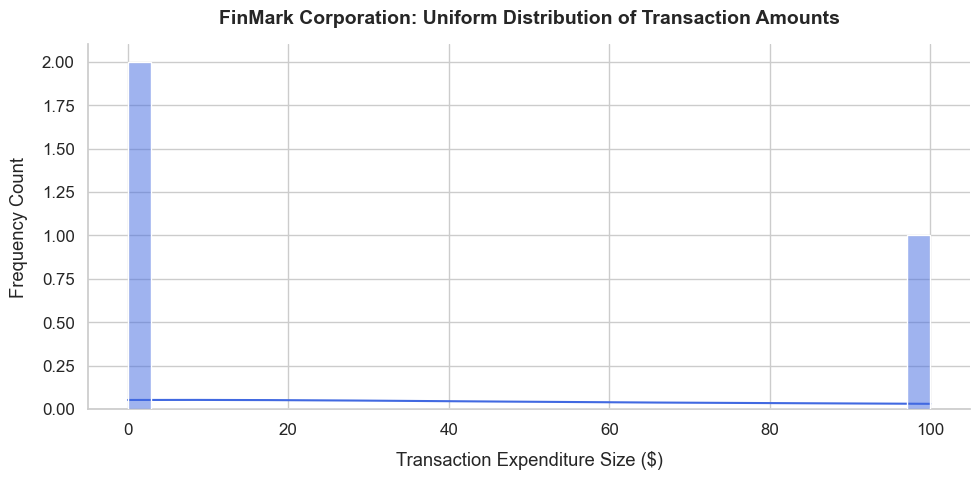

C:\Users\mmdcd\AppData\Local\Temp\ipykernel_23180\512519409.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_transactions, x=df_customers['IncomeLevel'], y='Amount', palette='Set2', zorder=3)


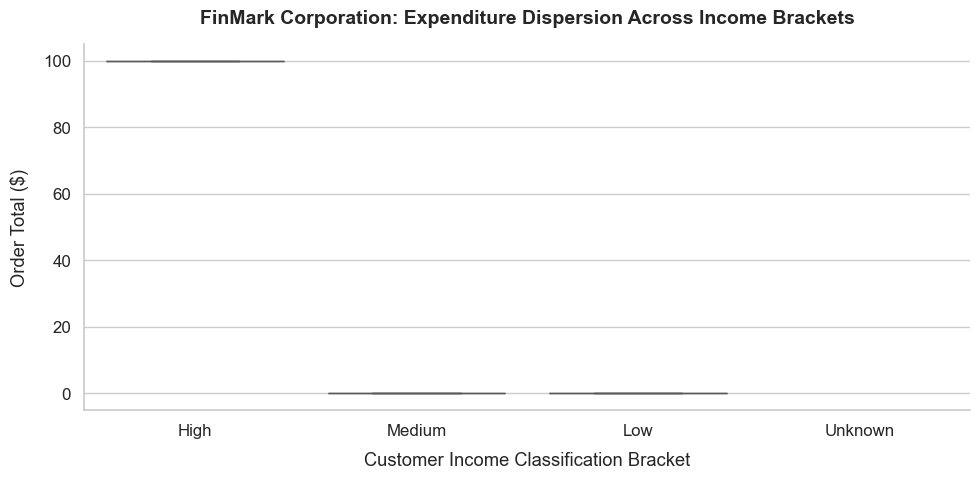

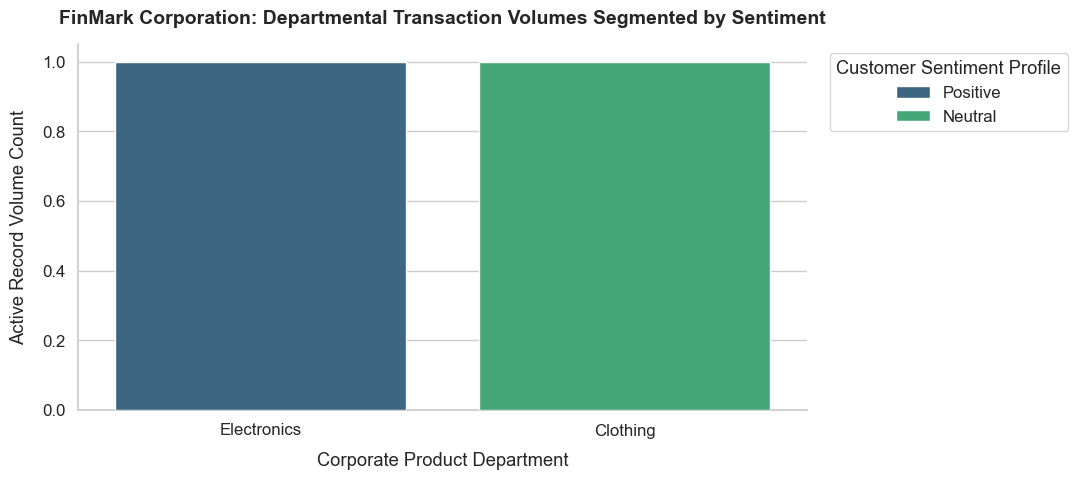

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df_customers = pd.read_csv('../data/cleaned_customers.csv')
df_transactions = pd.read_csv('../data/cleaned_transactions.csv')
df_interactions = pd.read_csv('../data/cleaned_interactions.csv')

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 5)

print("--- EXECUTING EXTENDED NUMERICAL COMPUTATIONS (NUMPY) ---")
age_array = np.array(df_customers['Age'].dropna())
print(f"Customer Age -> Mean: {np.mean(age_array):.2f} | Median: {np.median(age_array):.2f}")
print(f"Customer Age -> Std Dev: {np.std(age_array):.2f} | Variance: {np.var(age_array):.2f}")
print(f"Customer Age -> Min Bounds: {np.min(age_array)} | Max Bounds: {np.max(age_array)}\n")

amount_array = np.array(df_transactions['Amount'].dropna())
print(f"Transaction Cost -> Mean: ${np.mean(amount_array):.2f} | Median: ${np.median(amount_array):.2f}")
print(f"Transaction Cost -> Std Dev: ${np.std(amount_array):.2f} | Variance: ${np.var(amount_array):.2f}")

print("\nGenerating properly formatted pipeline charts...")

plt.figure()
sns.histplot(data=df_transactions, x='Amount', kde=True, color='royalblue', bins=35, zorder=3)
plt.title('FinMark Corporation: Uniform Distribution of Transaction Amounts', pad=15, weight='bold', fontsize=14)
plt.xlabel('Transaction Expenditure Size ($)', labelpad=10)
plt.ylabel('Frequency Count', labelpad=10)
sns.despine()
plt.tight_layout()
plt.show()

plt.figure()
sns.boxplot(data=df_transactions, x=df_customers['IncomeLevel'], y='Amount', palette='Set2', zorder=3)
plt.title('FinMark Corporation: Expenditure Dispersion Across Income Brackets', pad=15, weight='bold', fontsize=14)
plt.xlabel('Customer Income Classification Bracket', labelpad=10)
plt.ylabel('Order Total ($)', labelpad=10)
sns.despine()
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
sns.countplot(data=df_transactions, x='ProductCategory', hue=df_interactions['Sentiment'], palette='viridis', order=df_transactions['ProductCategory'].value_counts().index, zorder=3)
plt.title('FinMark Corporation: Departmental Transaction Volumes Segmented by Sentiment', pad=15, weight='bold', fontsize=14)
plt.xlabel('Corporate Product Department', labelpad=10)
plt.ylabel('Active Record Volume Count', labelpad=10)
plt.legend(title='Customer Sentiment Profile', bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()